In [1]:
#imports
import pandas as pd
import numpy as np
import pathlib

import sklearn.preprocessing as preprocessing
from sklearn import linear_model, metrics, model_selection
from sklearn.model_selection import train_test_split

import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns; sns.set_theme(style='ticks', context='talk')
sns.despine()

#import colorcet as cc



<Figure size 640x480 with 0 Axes>

In [2]:
#experiment name
experiment = '260915AKDER023'

#define same bool
save = True

#define path
save_path = pathlib.Path(r'..\processed_data')

#define task
task_df = pd.read_csv('sine_wave_25_min.csv', index_col=0)

#define data path
preprocessed_data = pd.read_csv(r'..\data\sine_wave_high_res_preprocessed_data.csv', index_col=0)

#plotting paras
colours = ['#069DC7','#A02B93', '#FFC000']
alphas = [1, 0.8]

#inputs 
input_names = ['y_value']

ss_time_sec = 15





In [3]:
def plot_func(task, axes, data_df, alpha, steps_ahead, colour, save = save, save_path = save_path):

    #plot sine wave
    sns.lineplot(x = task.index/60, y = task['y value'], color = 'k', ax=axes[0], alpha = 0.7, linestyle = '--')

    #plot prediciton on first axis
    sns.lineplot(data = data_df, x = data_df['forecast time (s)']/60, y = data_df['y predict'], 
                #hue = 'dataset', 
                style = data_df['dataset'],
                color = colour,
                markers=False, dashes = False,ax=axes[0], legend = False,
                alpha = alpha,
                lw = 3)
    
    #plot ASE on second axis
    sns.lineplot(x = data_df['forecast time (s)']/60, y = data_df['ase'], 
                #hue = 'dataset', 
                color = colour,
                style = data_df['dataset'], markers=False, dashes = False,ax=axes[1], legend = False,
                alpha = alpha,
                lw = 3)

    #set title
    axes[0].set_title(f"Sin wave prediction {steps_ahead*4.5} mins ahead")

    #set axes label
    axes[0].set_xlabel(r"")
    axes[1].set_xlabel(r"Time (min)")
    #def axis limits
    axes[1].set_ylim(0,2)
    axes[0].set_ylim(-0.1,1.1)
    axes[0].set_xlim(0,400)
    axes[1].set_xlim(0,400)

    #include horizontal line at 1 for ASE
    axes[1].axhline(y=1, color='gray', linestyle='--', linewidth=1)
    sns.despine()

    #vlines for train test split
    axes[0].vlines(x = ((data_df.loc[data_df['dataset'] == 'test', 'time (s)'].iloc[0]/60)+(steps_ahead-1))* 4.5, ymin = 0, ymax = 1.1, color = colour, alpha = 0.5, linestyle = '--', )
    axes[1].vlines(x = ((data_df.loc[data_df['dataset'] == 'test', 'time (s)'].iloc[0]/60)+(steps_ahead-1))* 4.5, ymin = 0, ymax = 1, color = colour, alpha = 0.5, linestyle = '--', )
    
    axes[1].set_ylabel("ASE")
    if save:
        plt.savefig(save_path/f"sine_wave_high_res_{steps_ahead*4.5}min_plot.svg", dpi = 900)

In [4]:

def task_prediction(df, task, steps_ahead = 1, save = save):
    
    df = df.copy()
    shift_value = -int(round((steps_ahead*270/ss_time_sec), 1))

    #define model and regularisation (sigma value)
    reg = linear_model.RidgeCV() 

    #define figure parameters
    fig1, axes = plt.subplots(2,1,figsize=(15,6), constrained_layout=True, gridspec_kw={'height_ratios': [5, 1]})

    #shift values to define predictions
    df['y forecast'] = df['y value'].shift(shift_value)

    #define column for time ahead to make plotting easier
    df['forecast time (s)'] = df['time (s)'].shift(shift_value)

    #replace na values
    df.dropna(inplace = True)

    input_cols = ['time (s)', 'y value', 'y forecast', 'forecast time (s)']

    #define time series
    U = df['forecast time (s)'].values
    X_chem = df.drop(input_cols, axis = 1)
    #U = preprocessing.MinMaxScaler().fit_transform(U_chem)
    X = preprocessing.StandardScaler().fit_transform(X_chem)

    y_index = df['y forecast'].values

    #train/test split
    U_train, U_test, X_train, X_test, y_train, y_test = train_test_split(U, X, y_index, train_size=0.8, shuffle=False)

    #train model
    reg.fit(X_train, y_train)

    #predict train set
    y_train_pred = reg.predict(X_train)
    y_train_pred = pd.DataFrame(y_train_pred, columns = ['y predict'])
    y_train_pred['forecast time (s)'] = U_train
    y_train_pred['dataset'] = 'train'

    #predict test set
    y_test_pred = reg.predict(X_test)
    y_test_pred = pd.DataFrame(y_test_pred, columns = ['y predict'])
    y_test_pred['forecast time (s)'] = U_test
    y_test_pred['dataset'] = 'test'



    predictions = pd.concat([y_train_pred, y_test_pred], axis = 0)
    predictions = predictions.set_index('forecast time (s)')
    prediction_df = df.join(predictions, on = 'forecast time (s)')

    # calculate absolute error
    prediction_df['difference'] = abs(prediction_df['y forecast'] - prediction_df['y predict'])

    #calculate ase
    standard_dev_train = np.std(y_train)
    prediction_df['ase'] = np.abs(prediction_df['difference']/ standard_dev_train)

    #calculate mase for test set of each group
    ase = prediction_df.loc[prediction_df['dataset'] =='test', 'ase'].mean()
    
    #plot predictions
    plot_func(task, axes, prediction_df, alpha = alphas[1], steps_ahead = steps_ahead, colour = colours[2], save = True)
    if save:
        prediction_df.to_csv(save_path/f'sine_wave_high_res_{steps_ahead*4.5}min_prediction.csv')

    return prediction_df, ase


0.1719711827627107
0.13253283729495863
0.15567915220254963
0.15480207324220147
0.13005870629910482


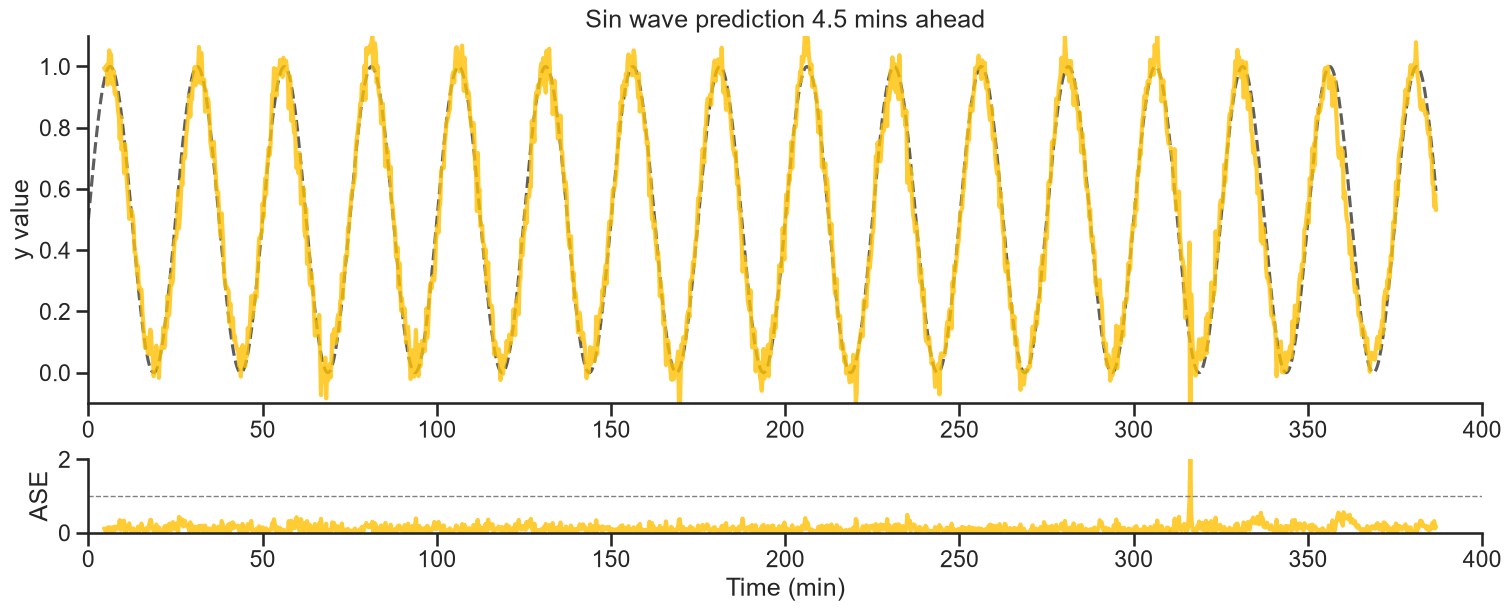

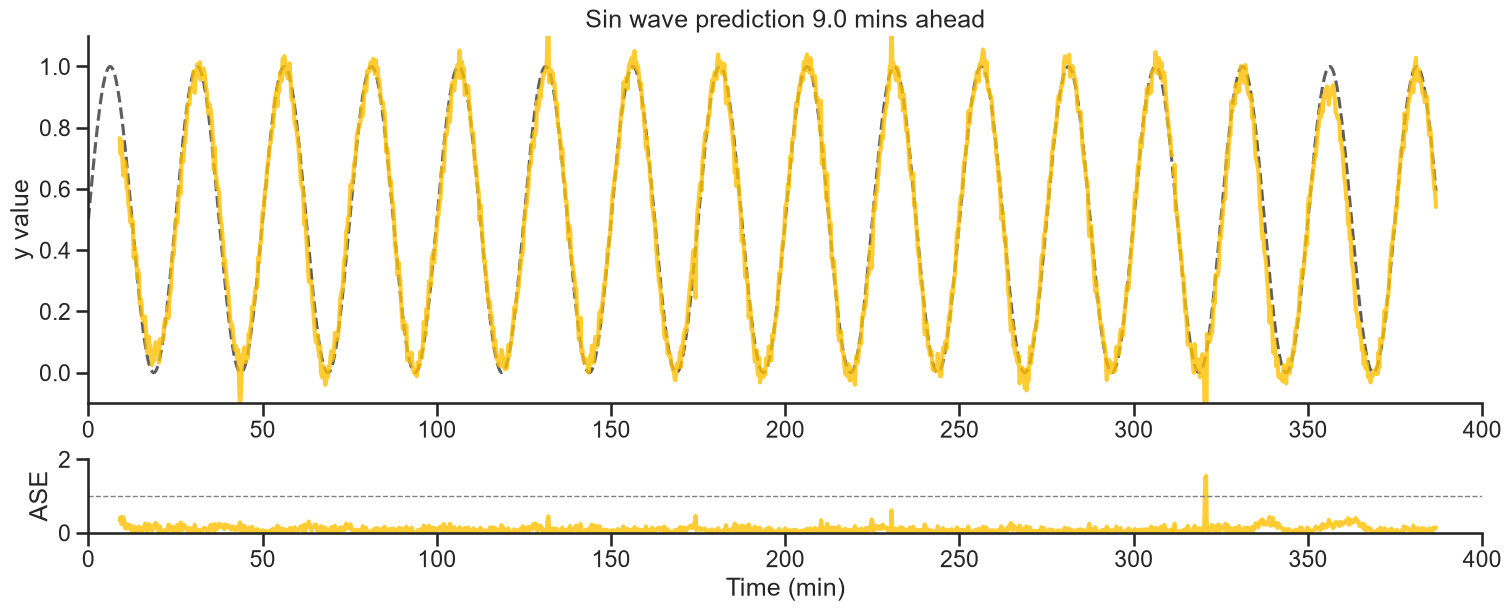

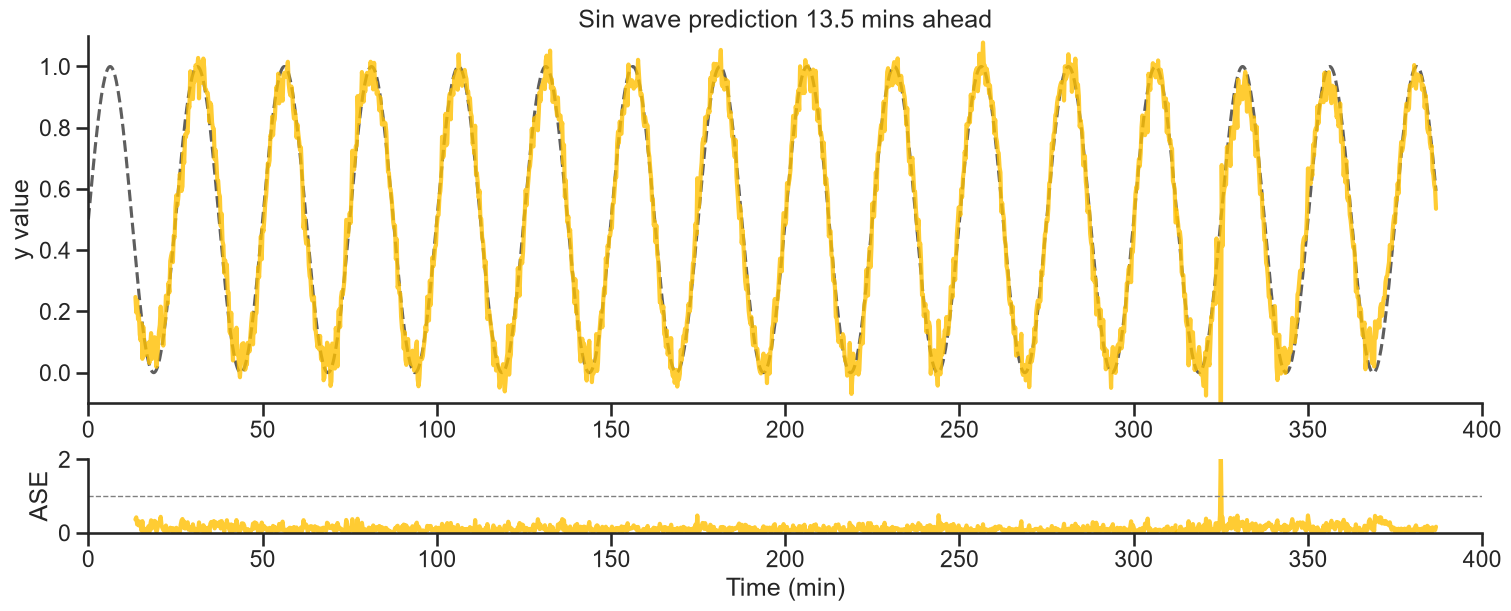

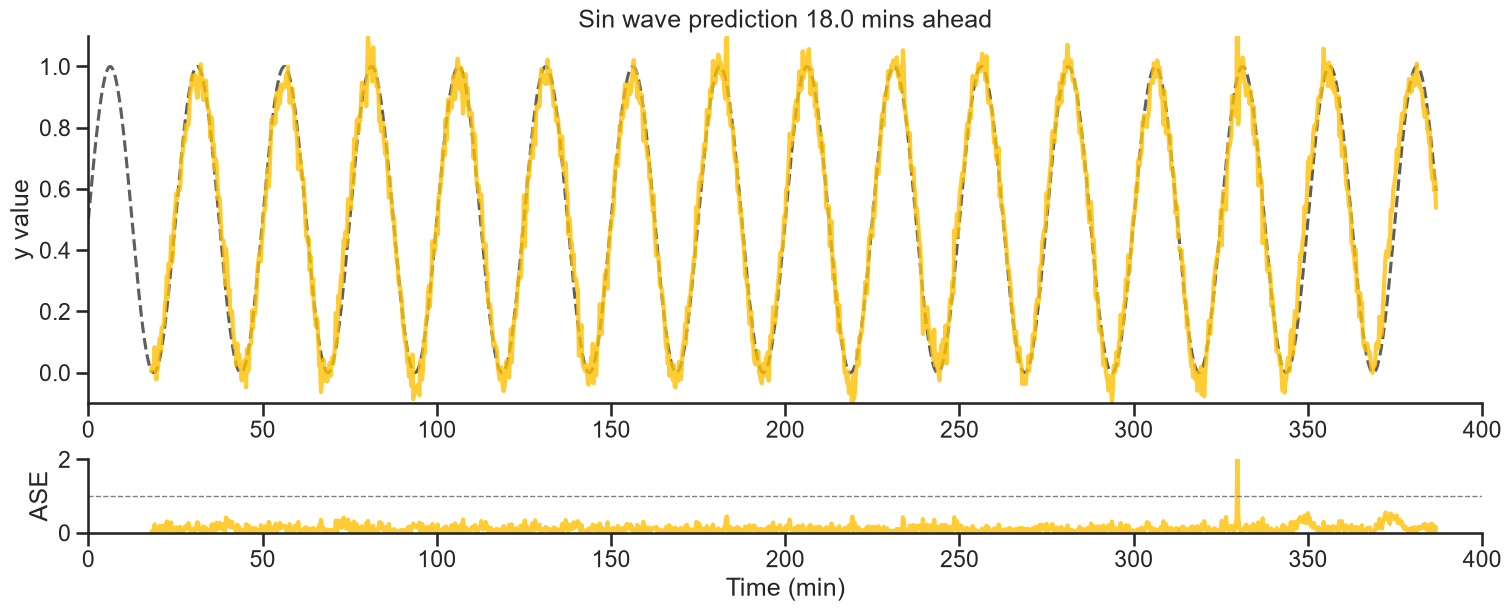

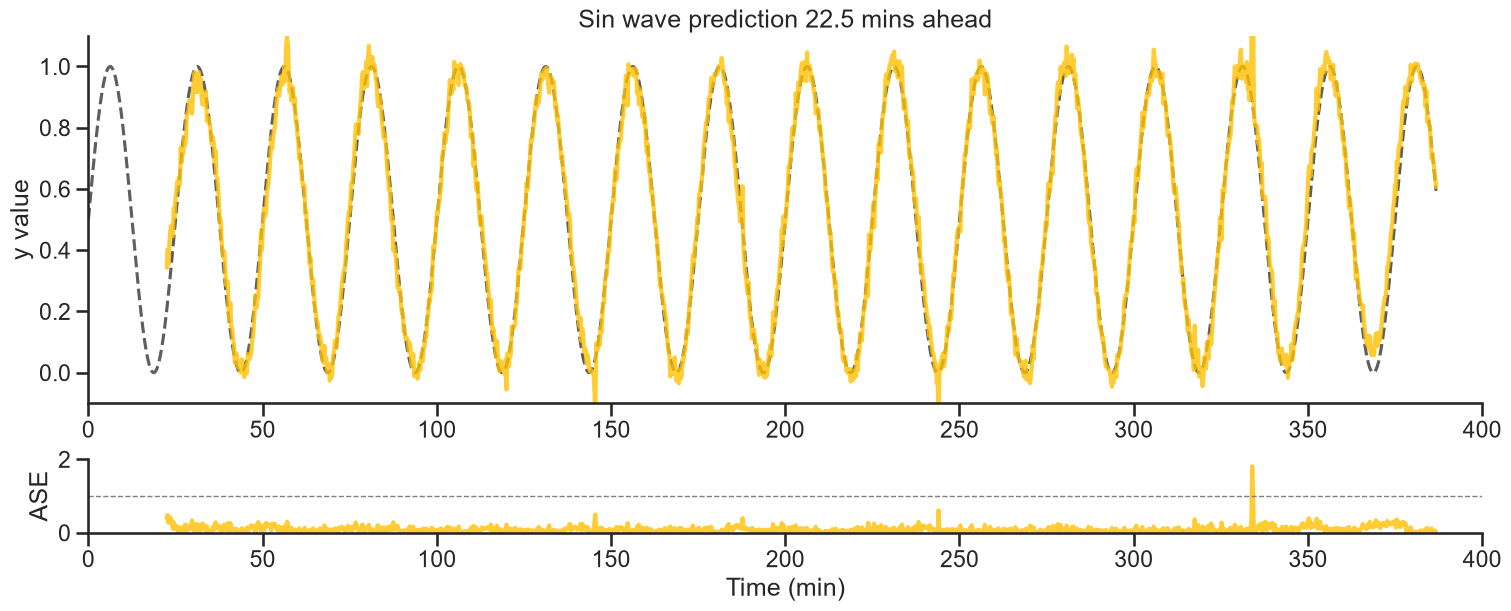

In [6]:
steps_ahead = [1,
               2,3,4,5
               ]

mase_score = pd.DataFrame()
step_pred_dict = {}

for step in steps_ahead:
    pred_steps, ase = task_prediction(preprocessed_data, task = task_df, steps_ahead= step)

    step_pred_dict[f'{step}'] = pred_steps
    print (ase)
    mase_score[step] = ase

